
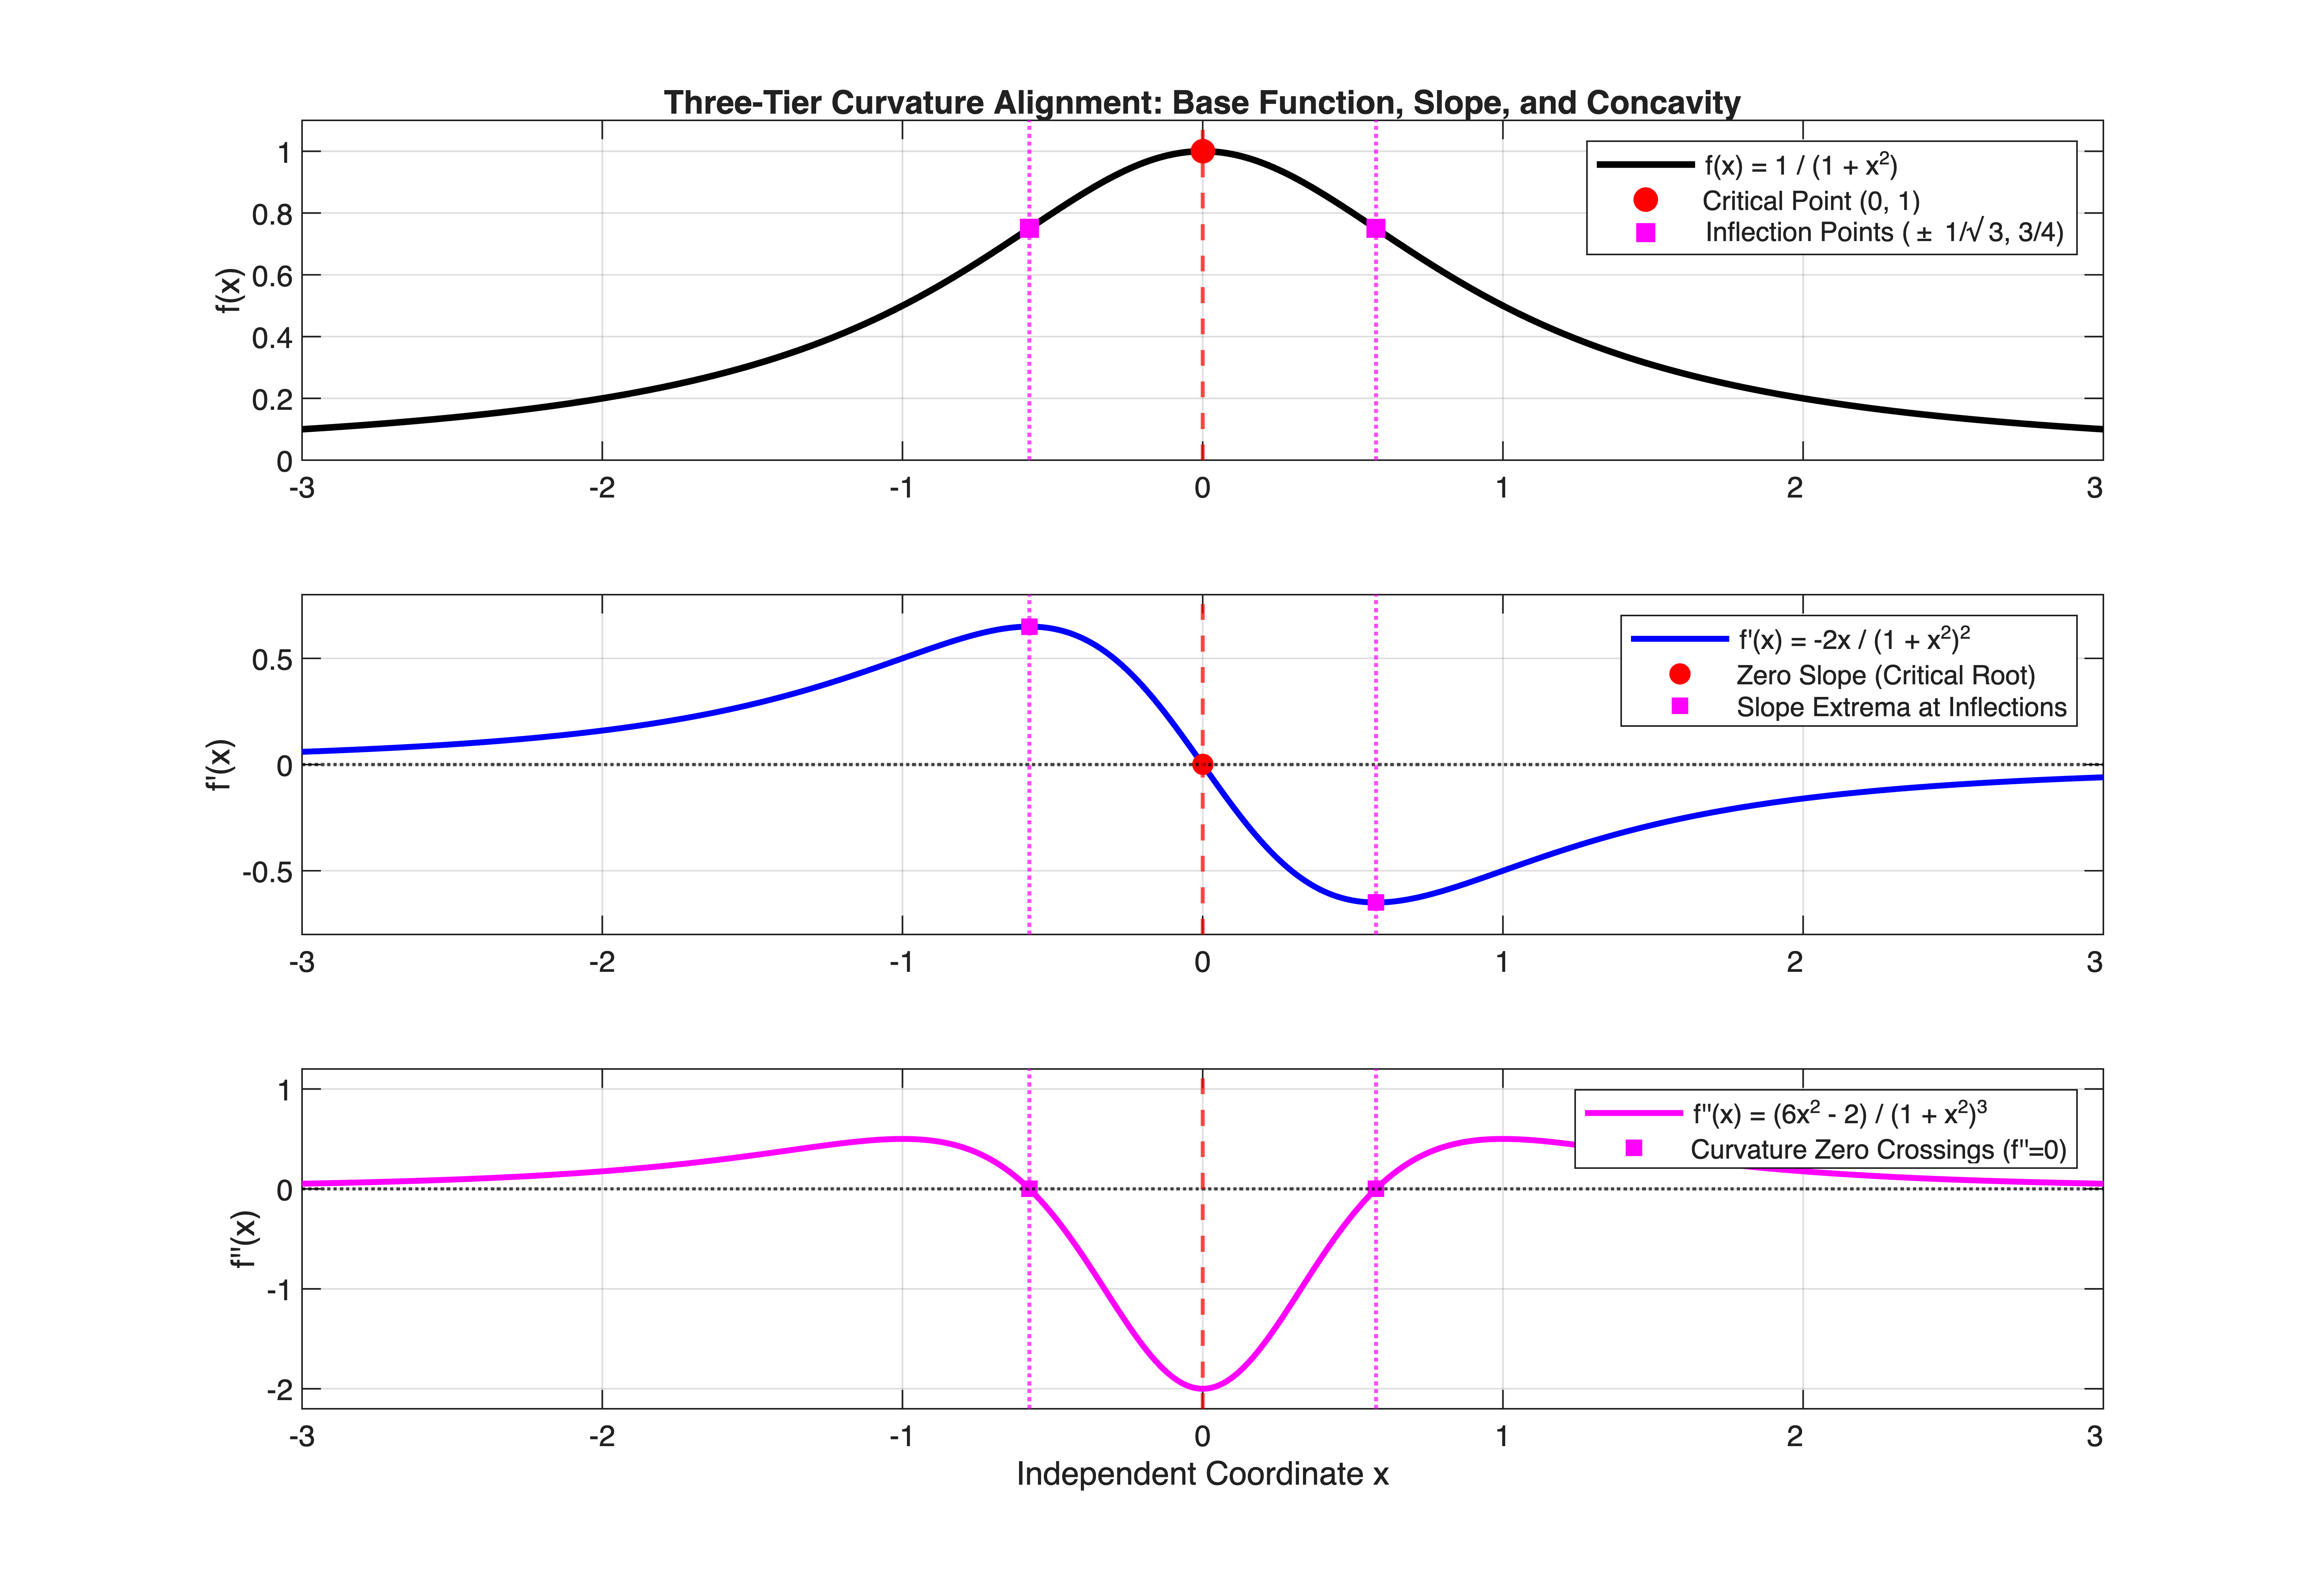

In [1]:
%% MIT 18.01 Problem Set 2 (2A & 2B): Curvature Topology & Surface Discretization
% Mathematical Tool Application: Aligns higher-order derivative extrema
% for curvature inflection detection (Runge benchmark) and evaluates geometric
% Taylor truncation error orders in curved surface mesh discretization.


clear; clc; close all;


%% Part 1: Three-Tier Aligned Analysis of Runge Function f(x) = 1 / (1 + x^2)
% Analytic functions derived in PS2B Problem 2
f_func   = @(x) 1 ./ (1 + x.^2);
df_func  = @(x) -2 * x ./ ((1 + x.^2).^2);
d2f_func = @(x) (6 * x.^2 - 2) ./ ((1 + x.^2).^3);


x_span = linspace(-3.0, 3.0, 500);
y_f   = f_func(x_span);
y_df  = df_func(x_span);
y_d2f = d2f_func(x_span);


% Characteristic points
x_crit = 0.0;
x_infl = [-1/sqrt(3), 1/sqrt(3)];


figure('Color', 'w', 'Position', [100, 50, 1100, 750]);


% Subplot 1: Base Function f(x)
sub1 = subplot(3, 1, 1);
plot(x_span, y_f, 'k-', 'LineWidth', 2.0, 'DisplayName', 'f(x) = 1 / (1 + x^2)'); hold on;
plot(x_crit, f_func(x_crit), 'ro', 'MarkerSize', 7, 'MarkerFaceColor', 'r', 'DisplayName', 'Critical Point (0, 1)');
plot(x_infl, f_func(x_infl), 'ms', 'MarkerSize', 7, 'MarkerFaceColor', 'm', ...
    'DisplayName', sprintf('Inflection Points (\\pm 1/\\surd 3, 3/4)'));
grid on; ylabel('f(x)'); xlim([-3, 3]); ylim([0, 1.1]);
title('Three-Tier Curvature Alignment: Base Function, Slope, and Concavity');
legend('Location', 'northeast');


% Subplot 2: First Derivative f'(x)
sub2 = subplot(3, 1, 2);
plot(x_span, y_df, 'b-', 'LineWidth', 1.8, 'DisplayName', 'f''(x) = -2x / (1 + x^2)^2'); hold on;
yline(0, 'k:', 'LineWidth', 1.0, 'HandleVisibility', 'off');
plot(x_crit, 0, 'ro', 'MarkerFaceColor', 'r', 'DisplayName', 'Zero Slope (Critical Root)');
plot(x_infl, df_func(x_infl), 'ms', 'MarkerFaceColor', 'm', 'DisplayName', 'Slope Extrema at Inflections');
grid on; ylabel('f''(x)'); xlim([-3, 3]); ylim([-0.8, 0.8]);
legend('Location', 'northeast');


% Subplot 3: Second Derivative f''(x)
sub3 = subplot(3, 1, 3);
plot(x_span, y_d2f, 'm-', 'LineWidth', 1.8, 'DisplayName', 'f''''(x) = (6x^2 - 2) / (1 + x^2)^3'); hold on;
yline(0, 'k:', 'LineWidth', 1.0, 'HandleVisibility', 'off');
plot(x_infl, [0, 0], 'ms', 'MarkerFaceColor', 'm', 'DisplayName', 'Curvature Zero Crossings (f''''=0)');
grid on; xlabel('Independent Coordinate x'); ylabel('f''''(x)'); xlim([-3, 3]); ylim([-2.2, 1.2]);
legend('Location', 'northeast');


% Add vertical alignment dashed lines across all three subplots
align_pts = [x_crit, x_infl];
colors_align = {'r--', 'm:', 'm:'};
for p = 1:length(align_pts)
    xp = align_pts(p);
    for s = [sub1, sub2, sub3]
        xline(s, xp, colors_align{p}, 'LineWidth', 1.2, 'HandleVisibility', 'off');
    end
end


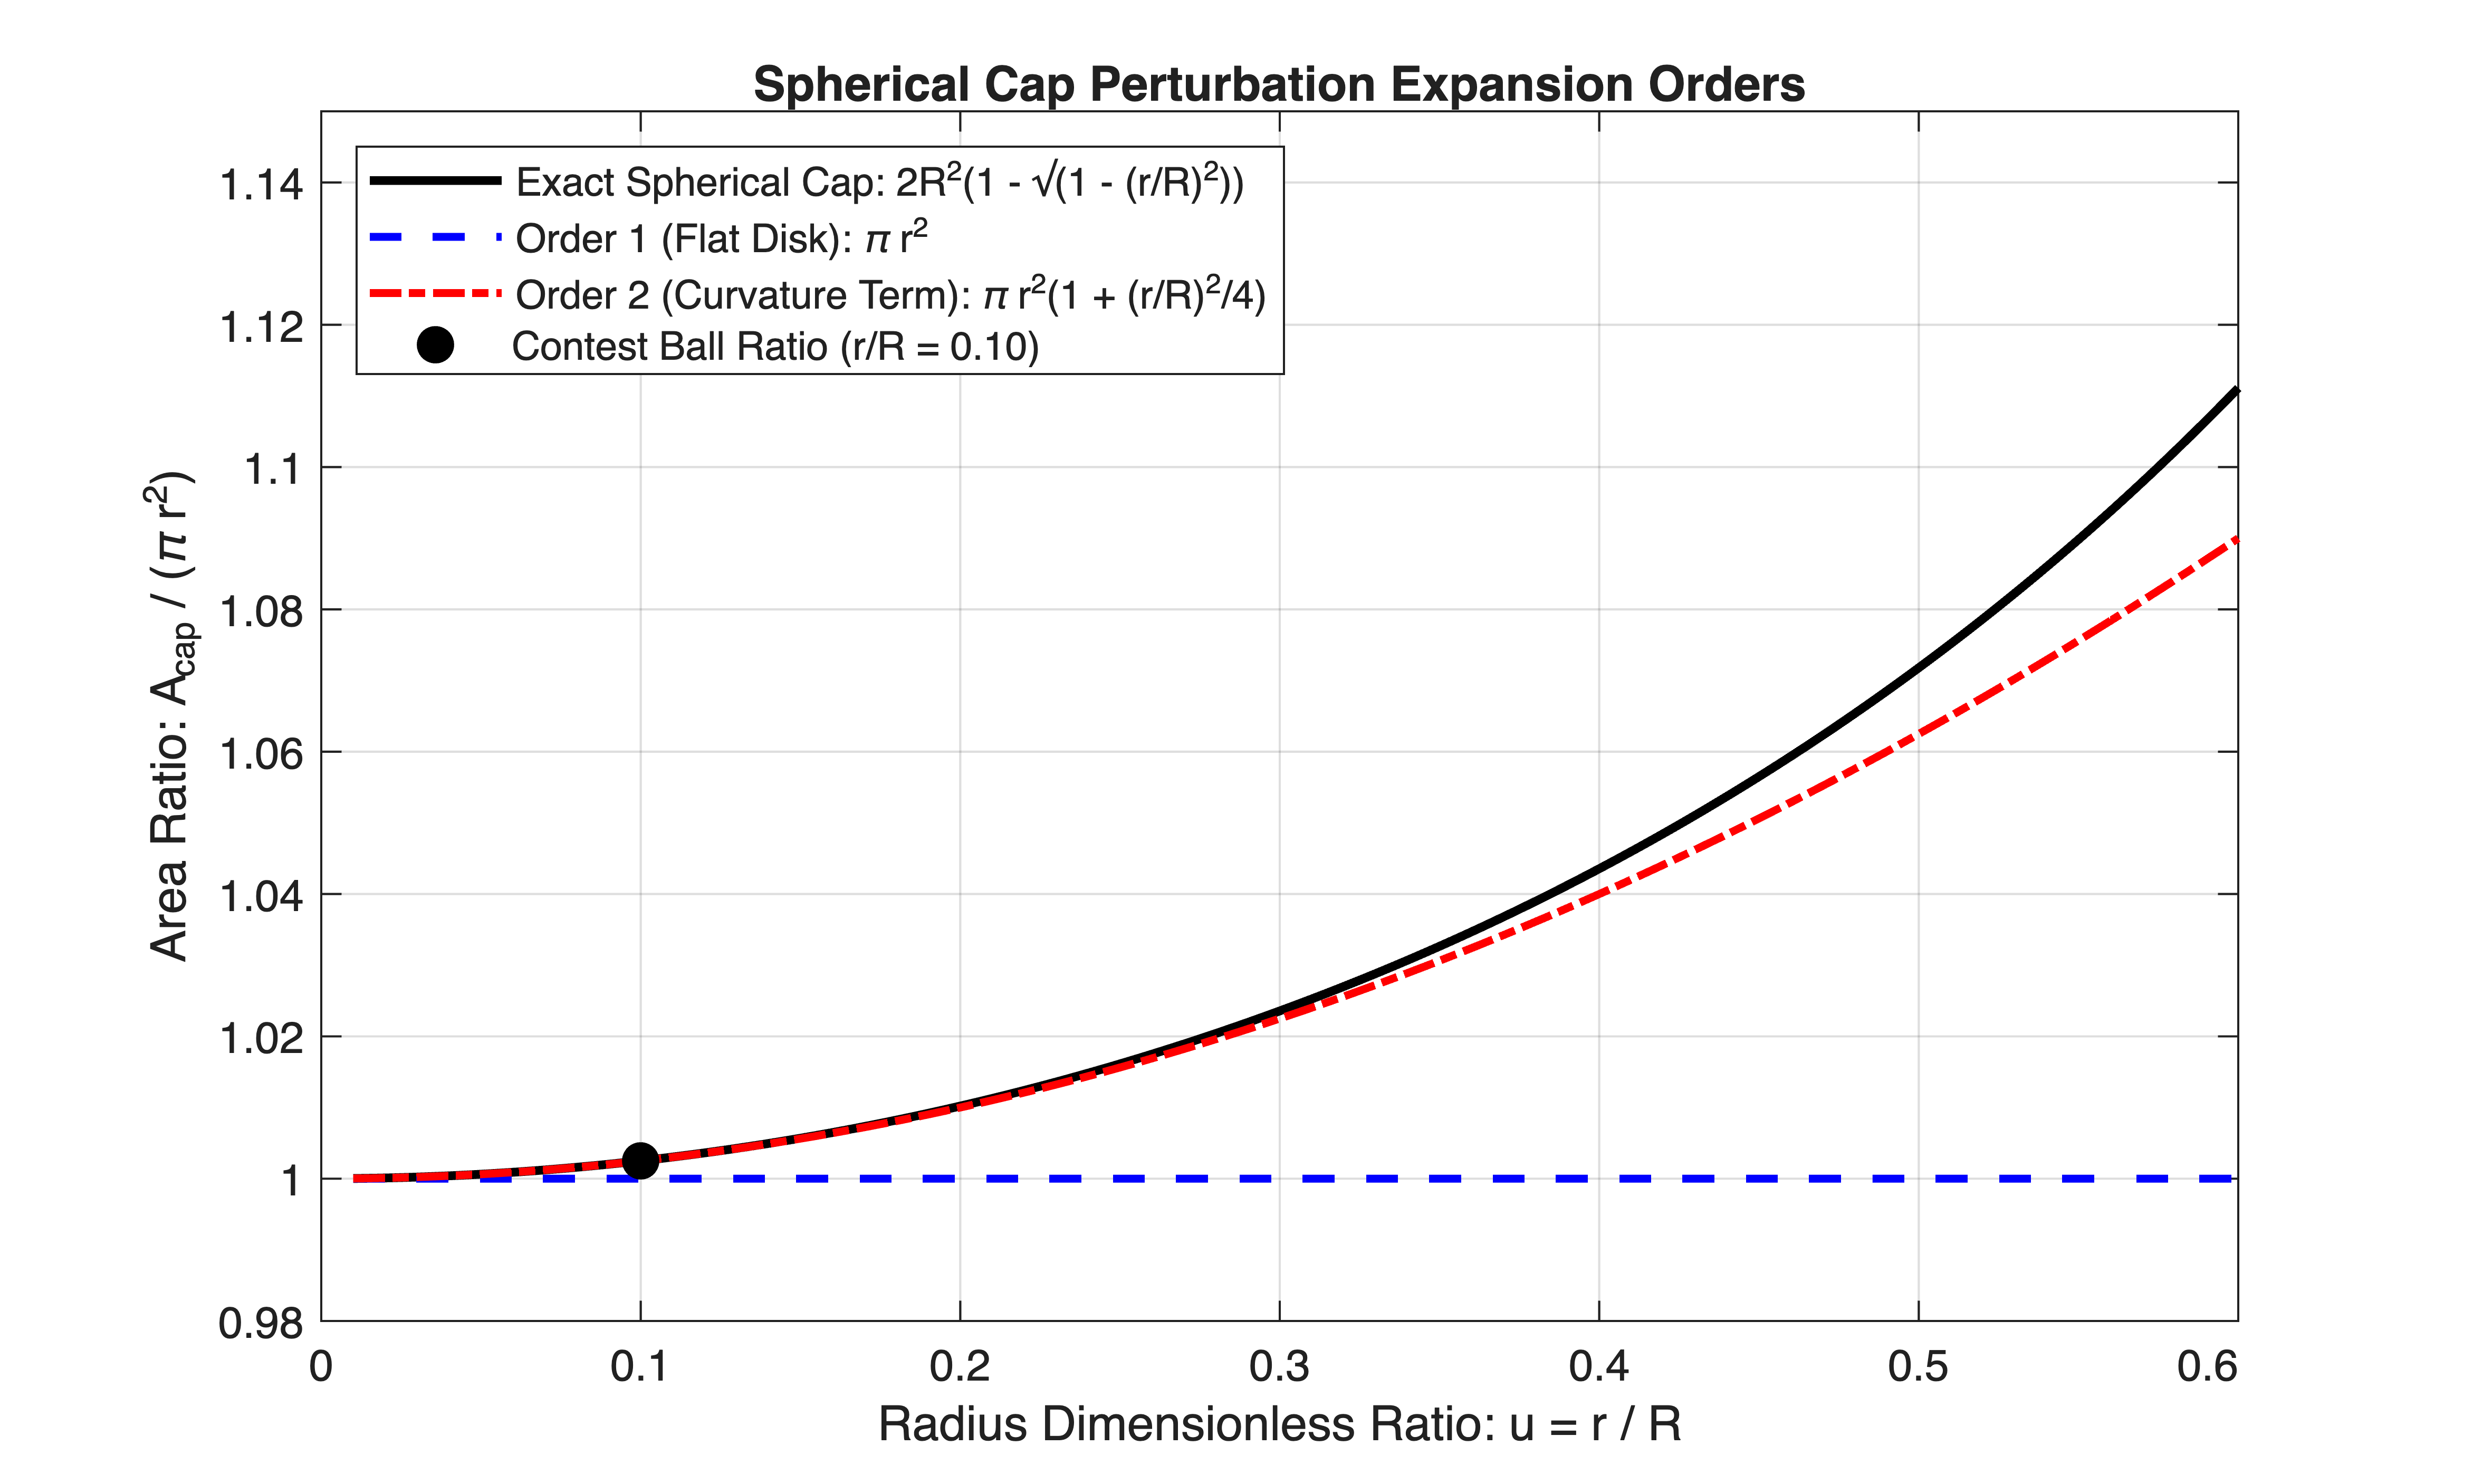

In [2]:


%% Part 2: Spherical Cap Area Perturbation vs. Exact (PS2B Problem 1)
% Normalized area: A_cap / (pi * r^2) as a function of aspect ratio u = r / R
u_ratio = linspace(0.01, 0.6, 300);


% Approximations:
% Exact:     A_cap / (pi*r^2) = 2 * (1 - sqrt(1 - u^2)) / u^2
% Flat Disk: A_flat / (pi*r^2) = 1.0
% Quadratic: A_quad / (pi*r^2) = 1.0 + 0.25 * u^2
norm_exact = 2 * (1 - sqrt(1 - u_ratio.^2)) ./ (u_ratio.^2);
norm_flat  = ones(size(u_ratio));
norm_quad  = 1.0 + 0.25 * (u_ratio.^2);


figure('Color', 'w', 'Position', [150, 150, 750, 450]);
plot(u_ratio, norm_exact, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Exact Spherical Cap: 2R^2(1 - \surd(1 - (r/R)^2))'); hold on;
plot(u_ratio, norm_flat, 'b--', 'LineWidth', 1.8, 'DisplayName', 'Order 1 (Flat Disk): \pi r^2');
plot(u_ratio, norm_quad, 'r-.', 'LineWidth', 1.8, 'DisplayName', 'Order 2 (Curvature Term): \pi r^2(1 + (r/R)^2/4)');


% Highlight golf ball operating ratio: r = 0.15 cm, R = 1.5 cm => u = 0.1
u_golf = 0.1;
plot(u_golf, 2 * (1 - sqrt(1 - u_golf^2)) / (u_golf^2), 'ko', 'MarkerFaceColor', 'k', 'MarkerSize', 8, ...
    'DisplayName', sprintf('Contest Ball Ratio (r/R = 0.10)'));


grid on;
xlabel('Radius Dimensionless Ratio: u = r / R');
ylabel('Area Ratio: A_{cap} / (\pi r^2)');
title('Spherical Cap Perturbation Expansion Orders');
legend('Location', 'northwest');
xlim([0, 0.6]); ylim([0.98, 1.15]);